# Session 10 - Generators & Coroutines

Generator Internals & Lifecycle

In [ ]:
def gen():
    print('inside gen() ', g.gi_running)
    yield 1
    yield 2

g = gen()
print(g.gi_frame)
print(g.gi_frame.f_lasti)
print(g.gi_running)
next(g)
print(g.gi_suspended)
print(g.gi_frame.f_lasti)
next(g)
print(g.gi_frame.f_lasti)
g.close()
print(g.gi_frame)

yield as a two way channel + send

In [ ]:
def accumulator():
    total = 0
    while True:
        x = yield total     # yield sends value OUT and waits for new value IN
        total += x

g = accumulator()
print(next(g))       # 0 (initial)
print(g.send(5))     # 5
print(g.send(10))    # 15

throw() & close()

In [ ]:
def worker():
    try:
        while True:
            try:
                x = yield
                print("got:", x)
            except ValueError:
                print("caught ValueError inside coroutine")
    except GeneratorExit:
        print("cleanup on close()")

w = worker()
next(w)

w.send(10)
w.throw(ValueError)
w.close()

Delegating Generators with yield from

In [ ]:
def sub():
    yield 1
    yield 2
    return 99

def outer():
    result = yield from sub()
    print("sub returned:", result)

g = outer()
print(list(g))

two way communication

In [ ]:
def sub_accumulator():
    """Subgenerator: yields current total, accepts a value via send().
       If it receives 'STOP', it returns the total (ends delegation)."""
    total = 0
    while True:
        # yield current total and wait for a send()
        x = yield total
        if x == 'STOP':
            return total      # StopIteration.value will carry this to outer
        total += x

def outer_delegate():
    print("outer: delegating to sub_accumulator()")
    # yield from delegates iteration, send, throw to sub_accumulator
    final = yield from sub_accumulator()
    print("outer: sub returned", final)
    # return or yield final back to caller (demonstrate returning as value)
    yield final

# Caller demo
if __name__ == "__main__":
    g = outer_delegate()
    print("caller -> created outer_delegate() =>", g)

    # The first next() advances into the sub and returns sub's first yield (initial total=0)
    print("caller -> next(g)  =>", next(g))   # prints outer delegation message too

    # send values; send() returns the next yielded value from the sub
    print("caller -> g.send(5)  =>", g.send(5))   # total becomes 5, yields 5
    print("caller -> g.send(10) =>", g.send(10))  # total becomes 15, yields 15

    # signal sub to stop and return final total
    # sending 'STOP' causes sub to return total; yield from completes and outer continues
    print("caller -> g.send('STOP') =>", g.send('STOP'))

    # After yield-final, the generator has one more yield (yield final)
    try:
        print("caller -> next(g) =>", next(g))
    except StopIteration:
        print("caller: outer finished")

**Assignment:** demonstrate exception propagation

## Coroutines

priming decorator

In [ ]:
def coroutine(func):
    def start(*args, **kwargs):
        cr = func(*args, **kwargs)
        next(cr)
        return cr
    return start

setup filtering pipeline

In [ ]:
@coroutine
def sink():
    while True:
        item = yield
        print("SINK:", item)

@coroutine
def filter_even(target):
    while True:
        n = yield
        if n % 2 == 0:
            target.send(n)


execute pipeline

In [ ]:
out = sink()
flt = filter_even(out)

for i in range(1, 10):
    flt.send(i)

flt.close()
out.close()

producer → filter → sink

A coroutine chain communicating above synchronously via .send()

In [17]:
# async version
async def async_filter(n):
    if n % 2 == 0:
        await target.put(n)

# Assignments
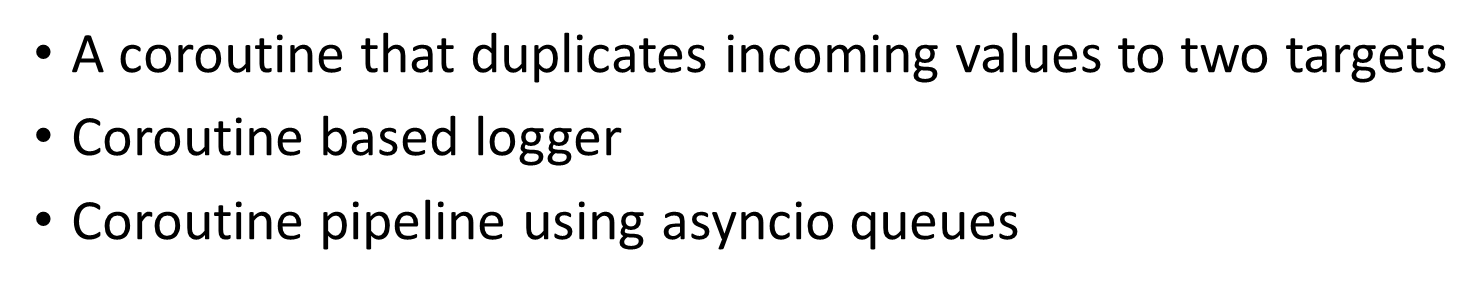